magine you are building a fraud detection system. You have thousands of transactions labeled as legitimate or fraudulent, and you need a classifier that not only separates them accurately but also has confidence in its predictions. A simple linear boundary might work, but what happens when your data is not neatly separable by a line? What if the pattern of fraud is hidden in a higher-dimensional space that your eyes cannot see?

This is where support vector machines (SVMs) shine. SVMs solve the problem of finding the optimal decision boundary: the one that maximizes the margin between classes, creating a robust classifier that generalizes well to new data. In this lesson, you will learn the geometric intuition behind SVMs, implement linear and non-linear classifiers, visualize how they carve up the feature space, and tune them for real-world performance.



Picture two groups of data points, such as tumors that are malignant and benign, or emails that are spam and not spam, scattered across a plot. A decision tree draws jagged boundaries; logistic regression draws a line where the data happens to pull it. A support vector machine does something different: it finds the line, or boundary, that sits as far as possible from both groups. That gap is the margin, and maximizing it is the key idea behind SVMs.

#### __Maximizing the margin between classes__

- Maximizing the **margin** gives the SVM a larger buffer between the decision boundary and the nearest training points.

- This makes the model **less sensitive to small changes or noise in the data** and improves generalisation to unseen data.

- A wider margin primarily guards against **overfitting**.


## __[Support vector machine]()__

How do support vector machines work?

The concept itself is quite simple. Let's pretend that we want to classify data points into group $A$ or group $B$. To do this, an SVM will plot our labelled training data as points in space and will look for the widest, clearest gap between points belonging to group A and points belonging to group B. It will then use this newly identified dividing line (known as a hyperplane) and the margin around it to classify new observations. An unseen data point will be classified into group A or B depending on which side of the margin it is closest to.

It's easy to do this when our data only has two features. We only need a simple one-dimensional decision boundary (which is basically a line) to classify the data. However, as more features get added the line needs to take on more dimensions because a simple line will no longer work. A line only has one dimension. A flat shape has two dimensions. A 3D shape (unsurprisingly) has three. What do we call something with four or more dimensions? In this case, it's a hyperplane. In SVM, the hyperplane will always have one less dimension ($-1$) than the number of input features ($p$), or a total of $(p-1)$ dimensions.

To explain it in more technical terms, the basic idea of the SVM is to separate points using a $(p - 1)$ dimensional hyperplane. What does it mean to separate points? This means that the SVM will construct a decision boundary such that points on the left are assigned a label of $A$ and points on the right are assigned a label of $B$.  When finding this separating hyperplane, we wish to maximise the distance of the nearest points to the hyperplane. The technical term for this is **maximum separating hyperplane**. The data points that dictate where the separating hyperplane goes are called **support vectors**. Have a look at a diagram of the margin, hyperplane, and support vectors below:

<div align="center" style=" font-size: 80%; text-align: center; margin: 0 auto">
<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/support_vector_machine_diagram.jpeg"  style="display: block; margin-left: auto; margin-right: auto;";/>
</div>

Read more about SVMs and how they work [here](https://en.wikipedia.org/wiki/Support_vector_machine).

SVMs are interesting models. Like logistic regression, they fit a linear decision boundary. However, unlike logistic regression, SVMs do this in a non-probabilistic way and are able to fit to non-linear data using an algorithm known as the [kernel trick](https://en.wikipedia.org/wiki/Kernel_method). Furthermore, SVMs can be used for` both classification and regression.` In `sklearn`, these are called `SVC` `(support vector classifier)` and `SVR` `(support vector regression)` respectively.

One important note: SVC can also refer to support vector **clustering**, so make sure to not get the two confused!

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

#### __[Synthetic Data]()__

In [2]:
from sklearn.datasets import make_gaussian_quantiles

# Set the feature dimensionality
p = 4

# Construct the dataset
X, y = make_gaussian_quantiles(
    cov=3.,
    n_samples=1000, n_features=p,
    n_classes=2, random_state=1
)

This code creates a **synthetic binary classification dataset** using Gaussian distributions.

The resulting data has:

* **1,000 observations**
* **4 features** → `X.shape = (1000, 4)`
* **2 classes** → binary classification
* `cov=3.` controls the covariance/dispersion of the Gaussian distribution.
* `random_state=1` ensures the same dataset is generated every time.

So conceptually:

$$X \rightarrow \text{4 numerical features}$$

$$y \rightarrow \text{binary target }(0,1)$$

This type of synthetic dataset is useful for demonstrating **classification algorithms such as SVMs**, particularly because the classes can have nonlinear boundaries.


In [3]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class distribution:")
print(np.bincount(y))

X shape: (1000, 4)
y shape: (1000,)
Class distribution:
[500 500]


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)    

This code **splits your dataset into training and testing sets**:

* **`X`** → input features (4 features)
* **`y`** → target/classes (0 or 1)
* **`test_size=0.2`** → 20% goes to testing, 80% to training
* **`random_state=42`** → makes the split reproducible

With 1,000 observations:

| Dataset   | Observations |
| --------- | -----------: |
| `X_train` |          800 |
| `X_test`  |          200 |
| `y_train` |          800 |
| `y_test`  |          200 |

So the model **learns from the 800 training observations** and is then **evaluated on the 200 observations it has not seen**.


### **[Exercise 1](): Fit a SVM classifier with a linear decision boundary**

We have a dataset with multiple features, and we want to classify the data into two classes using a support vector machine with a linear decision boundary. By fitting an SVC model with a linear kernel to the training data, we aim to create a decision boundary that separates the classes effectively.

For this exercise, do the following:
* Instantiate an SVC classifier with a linear kernel.
* Fit the classifier to the training data created above and make predictions on the test data.
* Print the accuracy score and classification report to evaluate the model's performance.

In [5]:
from sklearn.svm import SVC

In [6]:
# Instantiate the SVM classifier with a linear kernel
svc = SVC(kernel="linear")

# Fit the model on the training data
svc.fit(X_train, y_train)

# Make predictions on the test data
y_pred = svc.predict(X_test)

# Evaluate the model
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.5650

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.61      0.60       109
           1       0.52      0.52      0.52        91

    accuracy                           0.56       200
   macro avg       0.56      0.56      0.56       200
weighted avg       0.56      0.56      0.56       200



### **Interpretation**

* `kernel="linear"` forces the SVM to learn a **linear decision boundary**.
* `fit()` learns that boundary from `X_train` and `y_train`.
* `predict()` classifies the unseen `X_test` observations.
* **Accuracy** measures the overall proportion of correct predictions.
* The **classification report** provides precision, recall, and F1-score for each class.


### **[Exercise 2](): Plot the decision boundary for the SVC**
After fitting the SVM classifier with a linear kernel, we observe that the accuracy score was not as high as expected. To gain insights into the model's performance and understand why the accuracy was lower, we decided to visualise the decision boundary. By plotting the decision boundary in a two-dimensional space, we aim to visually inspect how well the linear boundary separates the classes.

For this exercise, do the following:
* Plot the decision boundary for the SVM classifier with a linear kernel.

Based on the visualisation of the decision boundary, what can we infer about the effectiveness of the linear decision boundary in separating the classes?

In [7]:
# Select two features
feature_1 = 0
feature_2 = 1

# Fit SVC using only the two selected features
svc.fit(X[:, [feature_1, feature_2]], y)

# Define feature ranges
x_min, x_max = X[:, feature_1].min(), X[:, feature_1].max()
y_min, y_max = X[:, feature_2].min(), X[:, feature_2].max()

# Create mesh grid
mesh_x, mesh_y = np.meshgrid(
    np.linspace(x_min, x_max, 1000),
    np.linspace(y_min, y_max, 1000)
)

# Create grid points for prediction
grid_points = np.c_[
    mesh_x.ravel(),
    mesh_y.ravel()
]

# Predict class for every point in the grid
grid_predictions = svc.predict(grid_points)

# Reshape predictions to match the mesh grid
grid_predictions = grid_predictions.reshape(mesh_x.shape)

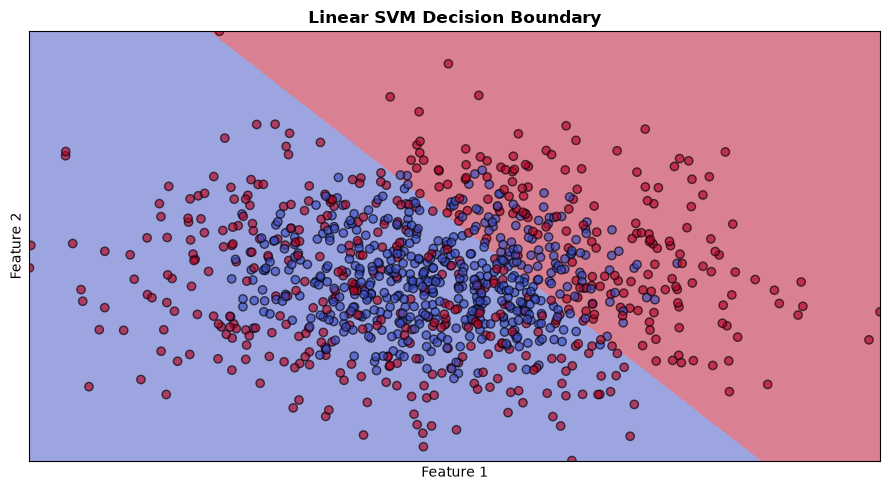

In [21]:
# Create figure and axes
fig = plt.figure(figsize=(9, 5))
ax = fig.add_subplot(111)

# Plot decision regions
ax.pcolormesh(
    mesh_x,
    mesh_y,
    grid_predictions,
    shading="nearest",
    cmap="coolwarm",
    alpha = 0.5
)

# Plot observations
ax.scatter(
    X[:, feature_1],
    X[:, feature_2],
    c=y,
    edgecolors="k",
    cmap="coolwarm",
    alpha = 0.65
)

# Add labels and limits
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Linear SVM Decision Boundary", fontweight="bold")

ax.set_xlim(mesh_x.min(), mesh_x.max())
ax.set_ylim(mesh_y.min(), mesh_y.max())

# Remove tick labels
ax.set_xticks(())
ax.set_yticks(())

plt.tight_layout()
plt.show()

### **Interpretation**

* The **purple and yellow observations heavily overlap** in the 2D projection.
* There is no clear straight-line separation between the classes.
* A linear SVM therefore has difficulty finding a boundary that correctly separates the two groups.
* This explains the relatively low classification accuracy.

**Conclusion:** The classes appear to have a **nonlinear relationship**, so a linear SVM is likely underfitting the data. A **nonlinear SVM, such as one using the RBF kernel**, would be more appropriate for capturing the curved/complex boundary between the classes.


### **[Exercise 3](): Fit a SVC classifier with a non-linear decision boundary**

Recognising the limitations of the linear decision boundary, fit an SVC model with an RBF kernel to the training data and evaluate its performance on the test set.

For this exercise, do the following:

* Use the provided code to fit an SVC model with an RBF kernel to the training data.
* Make predictions on the test data.
* Print the accuracy score and classification report to evaluate the performance of the model.

Did the use of the RBF kernel improve the accuracy of the SVM classifier compared to the linear kernel? Explain your answer.

In [9]:
# Instantiate the SVM classifier with an RBF kernel
rbf = SVC(kernel="rbf")

# Fit the model
rbf.fit(X_train, y_train)

# Make predictions
y_pred_rbf = rbf.predict(X_test)

# Evaluate the model
print(f"Accuracy: {accuracy_score(y_test, y_pred_rbf):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rbf))

Accuracy: 0.9800

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       109
           1       0.99      0.97      0.98        91

    accuracy                           0.98       200
   macro avg       0.98      0.98      0.98       200
weighted avg       0.98      0.98      0.98       200



> The RBF-based Support Vector Classifier achieved an accuracy of 98% on the test set, with an F1-score of 98% for both classes. Precision and recall were also highly balanced, ranging from 97% to 99%. This indicates that the model generalises very well to unseen observations and successfully captures non-linear patterns in the data. The balanced performance across both classes also suggests that the classifier does not systematically favour one class over the other.

### **[Exercise 4](): Plot the decision boundary for the SVC using the non-linear RBF kernel**

After observing a significant improvement in accuracy with the RBF kernel, your task is to visualise the decision boundary created by the non-linear RBF kernel in a two-dimensional space.

For this exercise, do the following:

* Plot the decision boundary for the SVM classifier with an RBF kernel.
* Compare the decision boundary visualisation of the RBF kernel with the linear kernel.
* Make observations about the differences between the two visualisations.

What differences do you observe, and how do these differences relate to the classification accuracy?

In [18]:
# Select two features
feature1 = 0
feature2 = 1

# Fit SVC using the selected features
rbf.fit(X[:, [feature1, feature2]], y)

# Define feature ranges
feature1_min = X[:, feature1].min()
feature1_max = X[:, feature1].max()

feature2_min = X[:, feature2].min()
feature2_max = X[:, feature2].max()

# Create mesh grid
mesh_x, mesh_y = np.meshgrid(
    np.linspace(feature1_min, feature1_max, 1000),
    np.linspace(feature2_min, feature2_max, 1000)
)

# Create grid points for prediction
grid_points = np.concatenate(
    (
        mesh_x.reshape(-1, 1),
        mesh_y.reshape(-1, 1)
    ),
    axis=1
)

# Predict classes across the grid
predictions = rbf.predict(grid_points)

# Reshape predictions to match the mesh
predictions = predictions.reshape(mesh_x.shape)

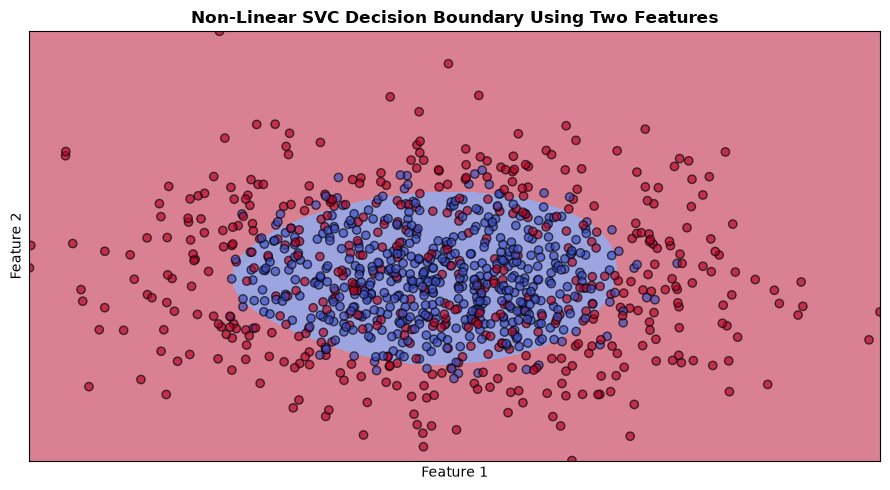

In [20]:
# Create figure and axes
fig = plt.figure(figsize=(9, 5))
ax = fig.add_subplot(111)

# Plot decision regions
ax.pcolormesh(
    mesh_x,
    mesh_y,   
    predictions,
    cmap= "coolwarm",
    alpha=0.5,
    shading="nearest"
)

# Plot observations
ax.scatter(
    X[:, feature1],
    X[:, feature2],
    c=y,
    cmap="coolwarm",
    alpha=0.65,
    edgecolors="k"
)

# Add labels
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Non-Linear SVC Decision Boundary Using Two Features", fontweight="bold")

# Set axis limits
ax.set_xlim(mesh_x.min(), mesh_x.max())
ax.set_ylim(mesh_y.min(), mesh_y.max())

# Remove tick labels
ax.set_xticks(())
ax.set_yticks(())


plt.tight_layout()
plt.show()

> The RBF SVC produces a distinctly non-linear decision boundary, in contrast to the straight-line boundary produced by the linear SVC. The curved boundary allows the model to capture more complex relationships between the predictors and the target, providing greater flexibility in separating the two classes.

> This increased flexibility is reflected in the model's performance, with the RBF SVC achieving 98% accuracy on the test set and an F1-score of 0.98 for both classes. The precision and recall values are also highly balanced, indicating that the model performs consistently across both classes.


| Aspect                       | Linear SVC     | RBF SVC            |
| ---------------------------- | -------------- | ------------------ |
| Boundary                     | Straight       | Curved/non-linear  |
| Flexibility                  | Low            | High               |
| Captures non-linear patterns | Limited        | Yes                |
| Complexity                   | Lower          | Higher             |
| Your test accuracy           | **56%**         | **98%**            |
| Interpretation               | Easier         | More complex       |
| Suitability here             | Less effective | **More effective** |


**Bottom line:** The visual difference between the two models explains why the RBF kernel can outperform the linear kernel: the RBF model has the flexibility to learn a non-linear structure that the linear model cannot represent


**Radial Basis Function (RBF) kernel**

### __[Hyperparameter Tuning of SVM]()__

In [16]:
# Define hyperparameter grid
parameters = {
    "kernel": ("linear", "rbf"),
    "C": (0.25, 1.0),
    "gamma": (1, 2)
}

# Create SVC model
svc = SVC()

# Perform grid search
grid_search = GridSearchCV(
    estimator=svc,
    param_grid=parameters,
    cv=5,
    scoring="accuracy"
)

# Fit the model
grid_search.fit(X_train, y_train)

# Make predictions using the best model
optimized_predictions = grid_search.predict(X_test)

# Evaluate the tuned model
optimized_accuracy = accuracy_score(
    y_test,
    optimized_predictions
)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)
print("Test accuracy of the tuned model:", optimized_accuracy)

Best parameters: {'C': 1.0, 'gamma': 1, 'kernel': 'rbf'}
Best cross-validation accuracy: 0.925
Test accuracy of the tuned model: 0.92


Hyperparameter tuning with techniques like GridSearchCV aims to optimise the SVM model's performance by finding the best combination of hyperparameters. GridSearchCV systematically searches through a predefined grid of hyperparameters and evaluates the model's performance using cross-validation. By selecting the hyperparameter combination that maximises a chosen performance metric, such as accuracy or F1-score, GridSearchCV helps improve the model's accuracy and generalisation ability. Overall, hyperparameter tuning ensures that the SVM model is trained with the most suitable settings for the given dataset, preventing overfitting or underfitting and enhancing its robustness across different datasets and conditions.